# 04 — Train and evaluate an LSTM for 5-class pose-based action recognition

This notebook consumes the sequence files created by `03_batch_extract_5class_and_build_sequences.ipynb`.

**Expected input folder:** `data/processed/sequences_5class/`

Expected arrays:
- `X_train.npy`, `X_val.npy`, `X_test.npy`: `(N, sequence_length, 51)`
- `y_train.npy`, `y_val.npy`, `y_test.npy`: integer class IDs
- `videos_train.npy`, `videos_val.npy`, `videos_test.npy`: source video path per sequence
- `label_map.json`: maps class IDs to names

The current project configuration is expected to use 16 sampled poses per sequence and 51 values per pose (17 COCO joints × x/y/confidence). This notebook checks the actual shapes rather than hard-coding the sequence length.

**Important:** this is a baseline experiment on a small dataset. Test metrics may be noisy, especially for classes with very few held-out windows. Do not interpret a single test score as proof of generalization to all videos or egocentric footage.

In [1]:
# Cell 1 — Imports and paths
from pathlib import Path
import json
import random
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

PROJECT_DIR = Path(r"C:\Users\admin\ViTPose_Action_Recognition")
SEQUENCE_DIR = PROJECT_DIR / "data" / "processed" / "sequences_5class"
OUTPUT_MODEL_DIR = PROJECT_DIR / "outputs" / "models"
OUTPUT_REPORT_DIR = PROJECT_DIR / "outputs" / "reports"

OUTPUT_MODEL_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_REPORT_DIR.mkdir(parents=True, exist_ok=True)

print("Project:", PROJECT_DIR)
print("Sequence data:", SEQUENCE_DIR)
print("Sequence folder exists:", SEQUENCE_DIR.is_dir())
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

assert SEQUENCE_DIR.is_dir(), f"Sequence folder not found: {SEQUENCE_DIR}"

Project: C:\Users\admin\ViTPose_Action_Recognition
Sequence data: C:\Users\admin\ViTPose_Action_Recognition\data\processed\sequences_5class
Sequence folder exists: True
PyTorch: 2.7.1+cu118
CUDA available: True
GPU: NVIDIA RTX A4000


In [2]:
# Cell 2 — Reproducibility and load data
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Use the GPU if available; the LSTM is small. Change to "cpu" if CUDA causes issues.
DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

required_files = [
    "X_train.npy", "y_train.npy", "X_val.npy", "y_val.npy",
    "X_test.npy", "y_test.npy", "videos_train.npy", "videos_val.npy",
    "videos_test.npy", "label_map.json"
]
missing = [name for name in required_files if not (SEQUENCE_DIR / name).is_file()]
assert not missing, f"Missing required sequence files: {missing}. Run the sequence-building cells first."

X_train = np.load(SEQUENCE_DIR / "X_train.npy", allow_pickle=False).astype(np.float32)
y_train = np.load(SEQUENCE_DIR / "y_train.npy", allow_pickle=False).astype(np.int64)
X_val = np.load(SEQUENCE_DIR / "X_val.npy", allow_pickle=False).astype(np.float32)
y_val = np.load(SEQUENCE_DIR / "y_val.npy", allow_pickle=False).astype(np.int64)
X_test = np.load(SEQUENCE_DIR / "X_test.npy", allow_pickle=False).astype(np.float32)
y_test = np.load(SEQUENCE_DIR / "y_test.npy", allow_pickle=False).astype(np.int64)

videos_train = np.load(SEQUENCE_DIR / "videos_train.npy", allow_pickle=False).astype(str)
videos_val = np.load(SEQUENCE_DIR / "videos_val.npy", allow_pickle=False).astype(str)
videos_test = np.load(SEQUENCE_DIR / "videos_test.npy", allow_pickle=False).astype(str)
label_map = json.loads((SEQUENCE_DIR / "label_map.json").read_text(encoding="utf-8"))
id_to_label = {int(k): str(v) for k, v in label_map.items()}
class_ids = sorted(id_to_label)
class_names = [id_to_label[i] for i in class_ids]
NUM_CLASSES = len(class_names)

print("Device:", DEVICE)
print("Label map:", id_to_label)
print("Train:", X_train.shape, y_train.shape, "source videos:", len(set(videos_train)))
print("Validation:", X_val.shape, y_val.shape, "source videos:", len(set(videos_val)))
print("Test:", X_test.shape, y_test.shape, "source videos:", len(set(videos_test)))

Device: cuda:0
Label map: {0: 'BenchPress', 1: 'Biking', 2: 'BoxingPunchingBag', 3: 'HorseRiding', 4: 'TennisSwing'}
Train: (184, 16, 51) (184,) source videos: 27
Validation: (73, 16, 51) (73,) source videos: 10
Test: (50, 16, 51) (50,) source videos: 7


In [3]:
# Cell 3 — Check shapes, labels, and video-level leakage before training
assert X_train.ndim == X_val.ndim == X_test.ndim == 3, "X arrays must have shape (N, T, F)."
assert X_train.shape[1] == X_val.shape[1] == X_test.shape[1], "Sequence lengths differ between splits."
assert X_train.shape[2] == X_val.shape[2] == X_test.shape[2] == 51, "Expected 51 features per frame (17 joints × x/y/confidence)."
assert len(X_train) == len(y_train) == len(videos_train)
assert len(X_val) == len(y_val) == len(videos_val)
assert len(X_test) == len(y_test) == len(videos_test)
assert len(X_train) > 0 and len(X_val) > 0 and len(X_test) > 0, "A split is empty. Do not train yet."

allowed_ids = set(class_ids)
for split_name, y in [("train", y_train), ("val", y_val), ("test", y_test)]:
    unknown = set(np.unique(y).tolist()) - allowed_ids
    assert not unknown, f"Unexpected class IDs in {split_name}: {unknown}"
    missing_classes = [id_to_label[i] for i in class_ids if i not in set(np.unique(y).tolist())]
    print(f"{split_name}: class counts =", {id_to_label[int(k)]: int(v) for k, v in zip(*np.unique(y, return_counts=True))})
    if missing_classes:
        print("  WARNING: no sequence examples for these classes in this split:", missing_classes)

train_videos, val_videos, test_videos = set(videos_train), set(videos_val), set(videos_test)
assert not (train_videos & val_videos), "Video leakage between train and validation."
assert not (train_videos & test_videos), "Video leakage between train and test."
assert not (val_videos & test_videos), "Video leakage between validation and test."

# Replace any accidental NaN/Inf values defensively, and report how many there were.
for name, arr in [("X_train", X_train), ("X_val", X_val), ("X_test", X_test)]:
    bad = int((~np.isfinite(arr)).sum())
    print(f"{name}: non-finite values before cleanup = {bad}")
    np.nan_to_num(arr, copy=False, nan=0.0, posinf=0.0, neginf=0.0)

SEQUENCE_LENGTH = X_train.shape[1]
INPUT_SIZE = X_train.shape[2]
print("\nValidated. Sequence length:", SEQUENCE_LENGTH, "features/frame:", INPUT_SIZE)
print("No source-video leakage detected.")

train: class counts = {'BenchPress': 21, 'Biking': 57, 'BoxingPunchingBag': 47, 'HorseRiding': 29, 'TennisSwing': 30}
val: class counts = {'BenchPress': 7, 'Biking': 16, 'BoxingPunchingBag': 20, 'HorseRiding': 11, 'TennisSwing': 19}
test: class counts = {'BenchPress': 2, 'Biking': 5, 'BoxingPunchingBag': 14, 'HorseRiding': 10, 'TennisSwing': 19}
X_train: non-finite values before cleanup = 0
X_val: non-finite values before cleanup = 0
X_test: non-finite values before cleanup = 0

Validated. Sequence length: 16 features/frame: 51
No source-video leakage detected.


## Model design

We will train a small LSTM classifier. For each sample, the LSTM receives an ordered sequence of normalized pose features and learns temporal patterns.

Because the training set is small and class counts differ, this notebook uses class-weighted cross-entropy, early stopping, and a validation set. These measures reduce but do not eliminate overfitting risk.

In [4]:
# Cell 4 — Make data loaders and define the LSTM
BATCH_SIZE = 16
HIDDEN_SIZE = 64
NUM_LAYERS = 1
DROPOUT = 0.25
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
MAX_EPOCHS = 80
PATIENCE = 12

train_dataset = TensorDataset(
    torch.from_numpy(X_train), torch.from_numpy(y_train)
)
val_dataset = TensorDataset(
    torch.from_numpy(X_val), torch.from_numpy(y_val)
)
test_dataset = TensorDataset(
    torch.from_numpy(X_test), torch.from_numpy(y_test)
)

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=0, pin_memory=(DEVICE.type == "cuda")
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=0, pin_memory=(DEVICE.type == "cuda")
)
test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=0, pin_memory=(DEVICE.type == "cuda")
)

class PoseLSTM(nn.Module):
    def __init__(self, input_size, hidden_size, num_layers, num_classes, dropout):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True
        )
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(hidden_size, num_classes)

    def forward(self, x):
        # x: (batch, sequence_length, features)
        _, (h_n, _) = self.lstm(x)
        final_hidden = h_n[-1]  # last layer's final hidden state
        return self.classifier(self.dropout(final_hidden))

model = PoseLSTM(
    input_size=INPUT_SIZE,
    hidden_size=HIDDEN_SIZE,
    num_layers=NUM_LAYERS,
    num_classes=NUM_CLASSES,
    dropout=DROPOUT
).to(DEVICE)

# Inverse-frequency class weights computed using only the training labels.
train_counts = np.bincount(y_train, minlength=NUM_CLASSES).astype(np.float32)
assert np.all(train_counts > 0), f"A class has zero training windows: {train_counts}"
class_weights = len(y_train) / (NUM_CLASSES * train_counts)
class_weights_t = torch.tensor(class_weights, dtype=torch.float32, device=DEVICE)

criterion = nn.CrossEntropyLoss(weight=class_weights_t)
optimizer = torch.optim.AdamW(
    model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY
)

print(model)
print("Train class counts:", {id_to_label[i]: int(train_counts[i]) for i in range(NUM_CLASSES)})
print("Class weights:", {id_to_label[i]: round(float(class_weights[i]), 3) for i in range(NUM_CLASSES)})
print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))

PoseLSTM(
  (lstm): LSTM(51, 64, batch_first=True)
  (dropout): Dropout(p=0.25, inplace=False)
  (classifier): Linear(in_features=64, out_features=5, bias=True)
)
Train class counts: {'BenchPress': 21, 'Biking': 57, 'BoxingPunchingBag': 47, 'HorseRiding': 29, 'TennisSwing': 30}
Class weights: {'BenchPress': 1.752, 'Biking': 0.646, 'BoxingPunchingBag': 0.783, 'HorseRiding': 1.269, 'TennisSwing': 1.227}
Trainable parameters: 30277


In [8]:
# Cell 5 — Training/evaluation helpers

def run_epoch(model, loader, train_mode):
    model.train(train_mode)
    total_loss = 0.0
    total = 0
    all_true, all_pred = [], []

    grad_context = torch.enable_grad if train_mode else torch.no_grad
    with grad_context():
        for xb, yb in loader:
            xb = xb.to(DEVICE, non_blocking=(DEVICE.type == "cuda"))
            yb = yb.to(DEVICE, non_blocking=(DEVICE.type == "cuda"))

            if train_mode:
                optimizer.zero_grad(set_to_none=True)

            logits = model(xb)
            loss = criterion(logits, yb)

            if train_mode:
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                optimizer.step()

            total_loss += float(loss.item()) * len(yb)
            total += len(yb)
            preds = logits.argmax(dim=1)
            all_true.extend(yb.detach().cpu().numpy().tolist())
            all_pred.extend(preds.detach().cpu().numpy().tolist())

    avg_loss = total_loss / max(total, 1)
    acc = accuracy_score(all_true, all_pred) if total else 0.0
    macro_f1 = f1_score(all_true, all_pred, labels=class_ids, average="macro", zero_division=0) if total else 0.0
    bal_acc = balanced_accuracy_score(all_true, all_pred) if total else 0.0
    return avg_loss, acc, macro_f1, bal_acc

print("Training helpers ready.")

Training helpers ready.


In [7]:
# Cell 6 — Train with early stopping and save the best validation model
MODEL_PATH = OUTPUT_MODEL_DIR / "lstm_action_model_5class.pt"
HISTORY_PATH = OUTPUT_REPORT_DIR / "lstm_5class_training_history.csv"

history = []
best_val_f1 = -1.0
best_val_loss = float("inf")
best_epoch = 0
best_state = None
epochs_without_improvement = 0

for epoch in range(1, MAX_EPOCHS + 1):
    train_loss, train_acc, train_f1, train_bal_acc = run_epoch(model, train_loader, train_mode=True)
    val_loss, val_acc, val_f1, val_bal_acc = run_epoch(model, val_loader, train_mode=False)

    row = {
        "epoch": epoch,
        "train_loss": train_loss,
        "train_accuracy": train_acc,
        "train_macro_f1": train_f1,
        "val_loss": val_loss,
        "val_accuracy": val_acc,
        "val_macro_f1": val_f1,
        "val_balanced_accuracy": val_bal_acc,
    }
    history.append(row)

    print(
        f"Epoch {epoch:02d}/{MAX_EPOCHS} | "
        f"train loss={train_loss:.4f}, acc={train_acc:.3f}, macro-F1={train_f1:.3f} | "
        f"val loss={val_loss:.4f}, acc={val_acc:.3f}, macro-F1={val_f1:.3f}",
        flush=True
    )

    improved = (val_f1 > best_val_f1 + 1e-6) or (
        abs(val_f1 - best_val_f1) <= 1e-6 and val_loss < best_val_loss
    )
    if improved:
        best_val_f1 = val_f1
        best_val_loss = val_loss
        best_epoch = epoch
        best_state = copy.deepcopy(model.state_dict())
        epochs_without_improvement = 0

        torch.save({
            "model_state": best_state,
            "input_size": INPUT_SIZE,
            "sequence_length": SEQUENCE_LENGTH,
            "hidden_size": HIDDEN_SIZE,
            "num_layers": NUM_LAYERS,
            "dropout": DROPOUT,
            "num_classes": NUM_CLASSES,
            "label_map": label_map,
            "best_epoch": best_epoch,
            "best_val_macro_f1": best_val_f1,
            "best_val_loss": best_val_loss,
        }, MODEL_PATH)
        print("  Saved new best model:", MODEL_PATH.name, flush=True)
    else:
        epochs_without_improvement += 1

    # Save history after each epoch so progress is retained if interrupted.
    pd.DataFrame(history).to_csv(HISTORY_PATH, index=False)

    if epochs_without_improvement >= PATIENCE:
        print(f"Early stopping: validation macro-F1 did not improve for {PATIENCE} epochs.")
        break

assert MODEL_PATH.is_file(), "No model checkpoint was saved."
print("\nTraining complete.")
print("Best epoch:", best_epoch)
print("Best validation macro-F1:", round(best_val_f1, 4))
print("Best model:", MODEL_PATH.resolve())
print("Training history:", HISTORY_PATH.resolve())

Epoch 01/80 | train loss=0.0513, acc=0.984, macro-F1=0.984 | val loss=2.2744, acc=0.575, macro-F1=0.527
  Saved new best model: lstm_action_model_5class.pt
Epoch 02/80 | train loss=0.1334, acc=0.967, macro-F1=0.965 | val loss=2.8086, acc=0.452, macro-F1=0.401
Epoch 03/80 | train loss=0.4068, acc=0.886, macro-F1=0.877 | val loss=1.7836, acc=0.589, macro-F1=0.514
Epoch 04/80 | train loss=0.1309, acc=0.951, macro-F1=0.944 | val loss=1.9828, acc=0.548, macro-F1=0.504
Epoch 05/80 | train loss=0.0187, acc=0.995, macro-F1=0.993 | val loss=1.7590, acc=0.644, macro-F1=0.577
  Saved new best model: lstm_action_model_5class.pt
Epoch 06/80 | train loss=0.0629, acc=0.978, macro-F1=0.977 | val loss=2.1475, acc=0.589, macro-F1=0.560
Epoch 07/80 | train loss=0.0858, acc=0.973, macro-F1=0.973 | val loss=2.1340, acc=0.575, macro-F1=0.550
Epoch 08/80 | train loss=0.0876, acc=0.978, macro-F1=0.979 | val loss=2.2726, acc=0.548, macro-F1=0.524
Epoch 09/80 | train loss=0.0189, acc=0.995, macro-F1=0.995 | val

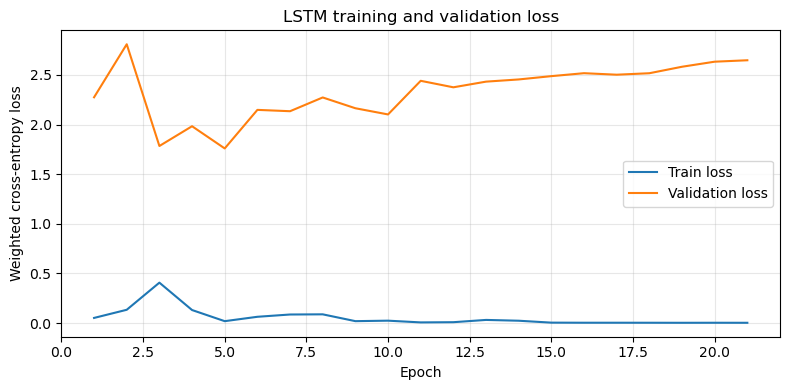

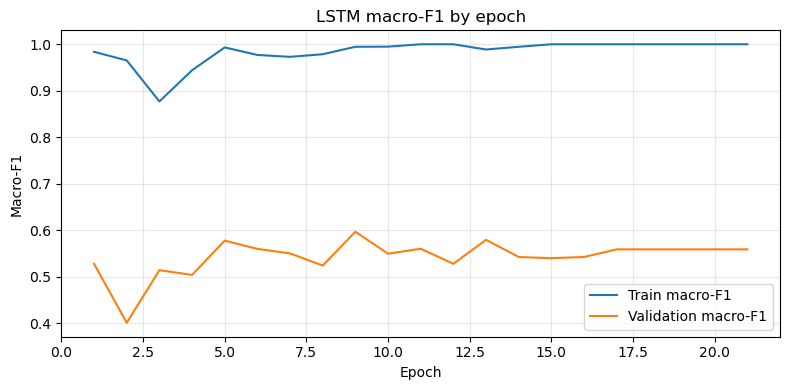

Saved plots: C:\Users\admin\ViTPose_Action_Recognition\outputs\reports\lstm_5class_loss.png and C:\Users\admin\ViTPose_Action_Recognition\outputs\reports\lstm_5class_macro_f1.png


In [9]:
# Cell 7 — Plot training history
hist_df = pd.read_csv(HISTORY_PATH)

plt.figure(figsize=(8, 4))
plt.plot(hist_df["epoch"], hist_df["train_loss"], label="Train loss")
plt.plot(hist_df["epoch"], hist_df["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Weighted cross-entropy loss")
plt.title("LSTM training and validation loss")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
loss_plot_path = OUTPUT_REPORT_DIR / "lstm_5class_loss.png"
plt.savefig(loss_plot_path, dpi=160)
plt.show()

plt.figure(figsize=(8, 4))
plt.plot(hist_df["epoch"], hist_df["train_macro_f1"], label="Train macro-F1")
plt.plot(hist_df["epoch"], hist_df["val_macro_f1"], label="Validation macro-F1")
plt.xlabel("Epoch")
plt.ylabel("Macro-F1")
plt.title("LSTM macro-F1 by epoch")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
f1_plot_path = OUTPUT_REPORT_DIR / "lstm_5class_macro_f1.png"
plt.savefig(f1_plot_path, dpi=160)
plt.show()

print("Saved plots:", loss_plot_path, "and", f1_plot_path)

In [10]:
# Cell 8 — Evaluate once on the held-out test set
# Test data is used only here, after model selection on validation data.
checkpoint = torch.load(MODEL_PATH, map_location=DEVICE, weights_only=True)

best_model = PoseLSTM(
    input_size=int(checkpoint["input_size"]),
    hidden_size=int(checkpoint["hidden_size"]),
    num_layers=int(checkpoint["num_layers"]),
    num_classes=int(checkpoint["num_classes"]),
    dropout=float(checkpoint["dropout"])
).to(DEVICE)
best_model.load_state_dict(checkpoint["model_state"], strict=True)
best_model.eval()

all_logits = []
all_predictions = []
with torch.inference_mode():
    for xb, _ in test_loader:
        logits = best_model(xb.to(DEVICE))
        all_logits.append(logits.cpu().numpy())
        all_predictions.extend(logits.argmax(dim=1).cpu().numpy().tolist())

y_pred = np.asarray(all_predictions, dtype=np.int64)
labels_all = list(range(NUM_CLASSES))

metrics = {
    "test_accuracy": float(accuracy_score(y_test, y_pred)),
    "test_balanced_accuracy": float(balanced_accuracy_score(y_test, y_pred)),
    "test_macro_f1": float(f1_score(y_test, y_pred, labels=labels_all, average="macro", zero_division=0)),
    "best_epoch": int(checkpoint["best_epoch"]),
    "best_validation_macro_f1": float(checkpoint["best_val_macro_f1"]),
    "test_windows": int(len(y_test)),
    "test_source_videos": int(len(set(videos_test))),
}

print("Best checkpoint epoch:", metrics["best_epoch"])
print("Test accuracy:", round(metrics["test_accuracy"], 4))
print("Test balanced accuracy:", round(metrics["test_balanced_accuracy"], 4))
print("Test macro-F1:", round(metrics["test_macro_f1"], 4))
print("Test windows:", metrics["test_windows"])
print("Test source videos:", metrics["test_source_videos"])

report_text = classification_report(
    y_test, y_pred, labels=labels_all,
    target_names=[id_to_label[i] for i in labels_all],
    zero_division=0
)
print("\nClassification report:\n")
print(report_text)

report_dict = classification_report(
    y_test, y_pred, labels=labels_all,
    target_names=[id_to_label[i] for i in labels_all],
    output_dict=True, zero_division=0
)
report_csv_path = OUTPUT_REPORT_DIR / "lstm_5class_classification_report.csv"
pd.DataFrame(report_dict).transpose().to_csv(report_csv_path)
metrics_path = OUTPUT_REPORT_DIR / "lstm_5class_test_metrics.json"
metrics_path.write_text(json.dumps(metrics, indent=2), encoding="utf-8")
print("Saved report:", report_csv_path.resolve())
print("Saved metrics:", metrics_path.resolve())

Best checkpoint epoch: 9
Test accuracy: 0.58
Test balanced accuracy: 0.6227
Test macro-F1: 0.5135
Test windows: 50
Test source videos: 7

Classification report:

                   precision    recall  f1-score   support

       BenchPress       0.14      1.00      0.25         2
           Biking       0.50      0.40      0.44         5
BoxingPunchingBag       0.14      0.07      0.10        14
      HorseRiding       1.00      0.80      0.89        10
      TennisSwing       0.94      0.84      0.89        19

         accuracy                           0.58        50
        macro avg       0.55      0.62      0.51        50
     weighted avg       0.65      0.58      0.60        50

Saved report: C:\Users\admin\ViTPose_Action_Recognition\outputs\reports\lstm_5class_classification_report.csv
Saved metrics: C:\Users\admin\ViTPose_Action_Recognition\outputs\reports\lstm_5class_test_metrics.json


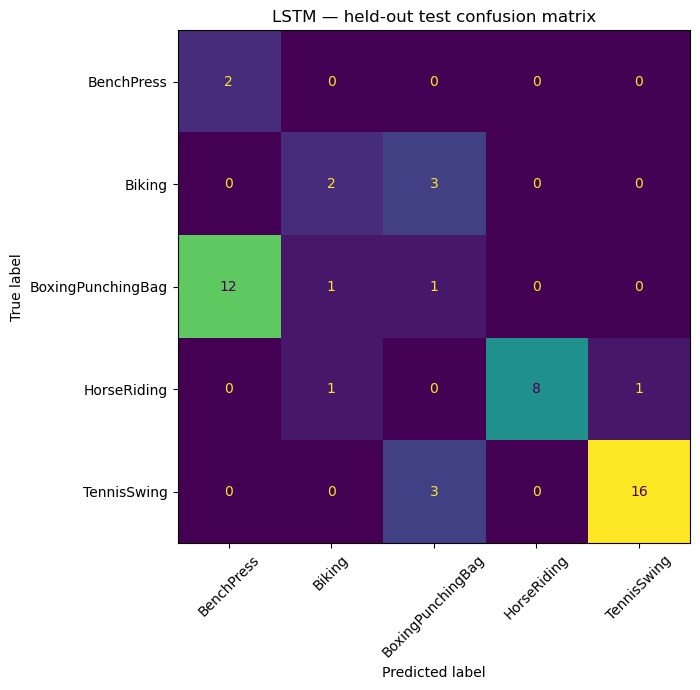

Saved confusion matrix: C:\Users\admin\ViTPose_Action_Recognition\outputs\reports\lstm_5class_confusion_matrix.png
       true_label   predicted_label
       BenchPress        BenchPress
       BenchPress        BenchPress
           Biking BoxingPunchingBag
           Biking BoxingPunchingBag
           Biking BoxingPunchingBag
           Biking            Biking
           Biking            Biking
BoxingPunchingBag            Biking
BoxingPunchingBag        BenchPress
BoxingPunchingBag        BenchPress
BoxingPunchingBag BoxingPunchingBag
BoxingPunchingBag        BenchPress
BoxingPunchingBag        BenchPress
BoxingPunchingBag        BenchPress
BoxingPunchingBag        BenchPress


In [11]:
# Cell 9 — Save and display the test confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=list(range(NUM_CLASSES)))
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[id_to_label[i] for i in range(NUM_CLASSES)]
)
fig, ax = plt.subplots(figsize=(8, 7))
display.plot(ax=ax, xticks_rotation=45, colorbar=False, values_format="d")
ax.set_title("LSTM — held-out test confusion matrix")
plt.tight_layout()
cm_path = OUTPUT_REPORT_DIR / "lstm_5class_confusion_matrix.png"
plt.savefig(cm_path, dpi=160)
plt.show()
print("Saved confusion matrix:", cm_path.resolve())

# Compare true vs predicted counts for quick sanity-check.
compare_df = pd.DataFrame({
    "true_label": [id_to_label[int(i)] for i in y_test],
    "predicted_label": [id_to_label[int(i)] for i in y_pred],
})
print(compare_df.head(15).to_string(index=False))

In [12]:
from pathlib import Path

ROOT = Path(r"C:\Users\admin\ViTPose_Action_Recognition")

for folder in [
    ROOT / "data" / "processed" / "keypoints",
    ROOT / "outputs" / "reports",
]:
    print(f"\n{folder}")
    print("Exists:", folder.exists())

    if folder.exists():
        for p in list(folder.rglob("*"))[:12]:
            print(p.relative_to(ROOT))


C:\Users\admin\ViTPose_Action_Recognition\data\processed\keypoints
Exists: True
data\processed\keypoints\.ipynb_checkpoints
data\processed\keypoints\ApplyEyeMakeup__v_ApplyEyeMakeup_g01_c04__e2cb58767c.npz
data\processed\keypoints\ApplyEyeMakeup__v_ApplyEyeMakeup_g01_c05__85feeac362.npz
data\processed\keypoints\ApplyEyeMakeup__v_ApplyEyeMakeup_g02_c01__560a140366.npz
data\processed\keypoints\ApplyEyeMakeup__v_ApplyEyeMakeup_g02_c02__fe57b9530b.npz
data\processed\keypoints\ApplyEyeMakeup__v_ApplyEyeMakeup_g02_c03__1adcc92044.npz
data\processed\keypoints\ApplyEyeMakeup__v_ApplyEyeMakeup_g02_c04__6f6b2def3a.npz
data\processed\keypoints\ApplyEyeMakeup__v_ApplyEyeMakeup_g03_c01__33dbf8fc73.npz
data\processed\keypoints\ApplyEyeMakeup__v_ApplyEyeMakeup_g03_c02__ac57e00f6e.npz
data\processed\keypoints\ApplyEyeMakeup__v_ApplyEyeMakeup_g03_c03__508b0a3b8a.npz
data\processed\keypoints\ApplyEyeMakeup__v_ApplyEyeMakeup_g03_c04__d24fb69143.npz
data\processed\keypoints\ApplyEyeMakeup__v_ApplyEyeMake

In [13]:

from pathlib import Path
import json
import pandas as pd

ROOT = Path.cwd()

# Find the project root if the notebook is inside the notebooks folder
if ROOT.name.lower() == "notebooks":
    ROOT = ROOT.parent

print("Project folder:", ROOT)

# 1. Check saved model
model_path = ROOT / "outputs" / "models" / "lstm_action_model_5class.pt"
print("\nMODEL CHECK")
print("Checkpoint exists:", model_path.exists())
if model_path.exists():
    print("Checkpoint size (MB):",
          round(model_path.stat().st_size / (1024 * 1024), 2))

# 2. Inspect reports
reports = ROOT / "outputs" / "reports"

print("\nREPORT FILES")
if reports.exists():
    for p in sorted(reports.iterdir()):
        if p.is_file():
            print(p.name)

# 3. Read training history
history_path = reports / "lstm_5class_training_history.csv"
if history_path.exists():
    history = pd.read_csv(history_path)
    print("\nTRAINING HISTORY")
    print(history.tail(15).to_string(index=False))
else:
    print("\nTraining history CSV not found.")

# 4. Read test metrics
metrics_path = reports / "lstm_5class_test_metrics.json"
if metrics_path.exists():
    print("\nTEST METRICS")
    print(metrics_path.read_text(encoding="utf-8"))
else:
    print("\nTest metrics JSON not found.")

# 5. Display classification report
report_path = reports / "lstm_5class_classification_report.csv"
if report_path.exists():
    print("\nCLASSIFICATION REPORT")
    print(pd.read_csv(report_path).to_string(index=False))


Project folder: C:\Users\admin\ViTPose_Action_Recognition

MODEL CHECK
Checkpoint exists: True
Checkpoint size (MB): 0.12

REPORT FILES
lstm_5class_classification_report.csv
lstm_5class_confusion_matrix.png
lstm_5class_loss.png
lstm_5class_macro_f1.png
lstm_5class_test_metrics.json
lstm_5class_training_history.csv

TRAINING HISTORY
 epoch  train_loss  train_accuracy  train_macro_f1  val_loss  val_accuracy  val_macro_f1  val_balanced_accuracy
     7    0.085831        0.972826        0.972908  2.134033      0.575342      0.549862               0.575661
     8    0.087590        0.978261        0.978553  2.272576      0.547945      0.523788               0.574233
     9    0.018886        0.994565        0.994571  2.163948      0.630137      0.596471               0.604064
    10    0.023699        0.994565        0.994871  2.101518      0.616438      0.549325               0.577753
    11    0.006269        1.000000        1.000000  2.440338      0.589041      0.559975               0.5

## Interpretation and limitations

- A model checkpoint, training history, classification report, metrics JSON, and confusion matrix are saved under `outputs/`.
- The test set is small (in the current run, roughly 50 windows from 7 videos), and some classes have very few test windows. Per-class scores can therefore move sharply with one prediction.
- Multiple sequence windows from one source video are allowed in the same split, but the sequence builder must keep each source video entirely within one split. This notebook checks that condition.
- Pose extraction currently selects the largest person independently in each sampled frame; it does not ensure a persistent person identity. Errors in the extracted poses can affect action classification.
- UCF101 videos are mostly third-person footage. Results do not establish performance on egocentric video. Test that domain separately after this baseline works.
- Do not report only accuracy. Include macro-F1, per-class precision/recall, the confusion matrix, the number of held-out videos, and the limitations above.

### Output files
- `outputs/models/lstm_action_model_5class.pt`
- `outputs/reports/lstm_5class_training_history.csv`
- `outputs/reports/lstm_5class_loss.png`
- `outputs/reports/lstm_5class_macro_f1.png`
- `outputs/reports/lstm_5class_classification_report.csv`
- `outputs/reports/lstm_5class_test_metrics.json`
- `outputs/reports/lstm_5class_confusion_matrix.png`